# 06 · AdamW、梯度累积和学习率计划

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 训练细节

参考上游 `train.py`：warmup + cosine 学习率、`gradient_accumulation_steps`、AdamW 的 2D/1D 参数组。**关键点：** 累积微批次时，loss 必须按累积次数缩放（这里微批大小相等）。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


LR start: 0.00025 warmup: 0.003 end: 0.0003


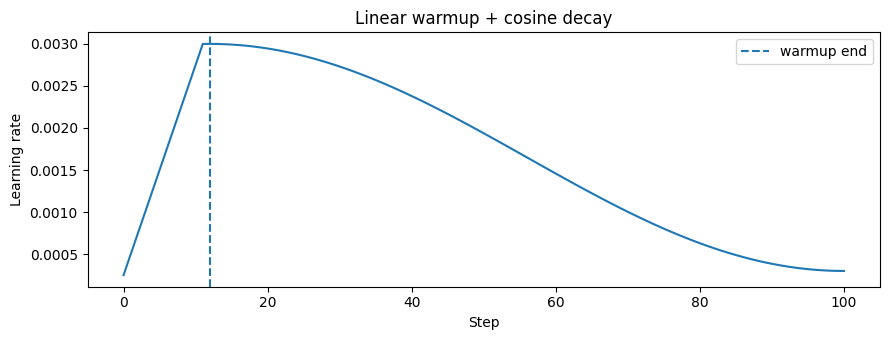

In [2]:
steps=100;warmup=12;max_lr=3e-3;min_lr=3e-4
learning_rates=np.array([lr_schedule(i,steps,warmup,max_lr,min_lr) for i in range(steps+1)])
print('LR start:',learning_rates[0],'warmup:',learning_rates[warmup],'end:',learning_rates[-1])
assert learning_rates[-1] == min_lr
fig,ax=plt.subplots(figsize=(9,3.5));ax.plot(learning_rates);ax.axvline(warmup,linestyle='--',label='warmup end')
ax.set_xlabel('Step');ax.set_ylabel('Learning rate');ax.set_title('Linear warmup + cosine decay');ax.legend();fig.tight_layout()
fig.savefig(FIG/'06_lr_schedule.png',dpi=130);display(fig);plt.close(fig)

Large batch size: 6 micro batches: 3 x 2 max gradient delta: 2.9802322387695312e-08


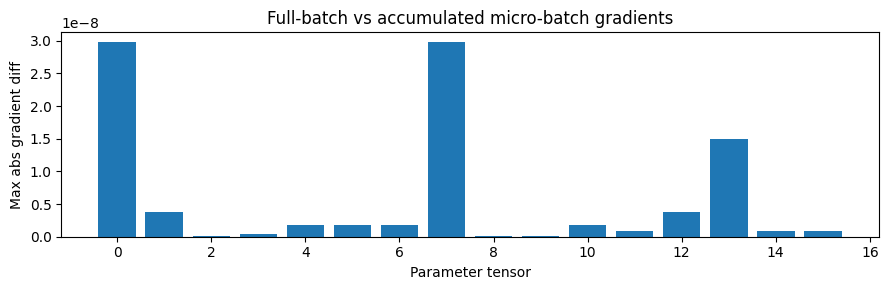

In [3]:
import copy
ids,stoi,itos=char_dataset(training_text(repeats=6))
cfg=GPTConfig(vocab_size=len(stoi),block_size=12,n_layer=1,n_head=2,n_embd=16)
model_full=GPT(cfg).eval();model_micro=copy.deepcopy(model_full).eval()
x,y=get_batch(ids,cfg.block_size,6,generator=torch.Generator().manual_seed(123))
_,loss_full=model_full(x,y);loss_full.backward()
for xx,yy in zip(x.chunk(3),y.chunk(3)):
    _,micro_loss=model_micro(xx,yy)
    (micro_loss/3).backward()
comparisons=[]
for (name,p1),(name2,p2) in zip(model_full.named_parameters(),model_micro.named_parameters()):
    assert name==name2
    comparisons.append((name,(p1.grad-p2.grad).abs().max().item()))
worst=max(d for name,d in comparisons)
print('Large batch size:',len(x),'micro batches: 3 x 2','max gradient delta:',worst)
assert worst < 1e-5
fig,ax=plt.subplots(figsize=(9,3));ax.bar(range(len(comparisons)),[d for _,d in comparisons]);ax.set_xlabel('Parameter tensor');ax.set_ylabel('Max abs gradient diff');ax.set_title('Full-batch vs accumulated micro-batch gradients');fig.tight_layout()
fig.savefig(FIG/'06_gradient_accumulation.png',dpi=130);display(fig);plt.close(fig)

Weight decay (>=2D): 3696 parameters; no decay (<2D): 240
Distinct groups weight_decay: [0.1, 0.0]


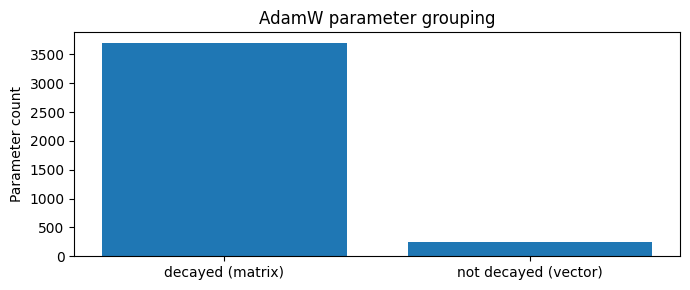

In [4]:
groups=parameter_groups(model_full,weight_decay=.1)
counts=[sum(p.numel() for p in g['params']) for g in groups]
print('Weight decay (>=2D):',counts[0],'parameters; no decay (<2D):',counts[1])
print('Distinct groups weight_decay:',[g['weight_decay'] for g in groups])
assert sum(counts)==sum(p.numel() for p in model_full.parameters())
fig,ax=plt.subplots(figsize=(7,3));ax.bar(['decayed (matrix)','not decayed (vector)'],counts);ax.set_ylabel('Parameter count');ax.set_title('AdamW parameter grouping');fig.tight_layout()
fig.savefig(FIG/'06_adamw_groups.png',dpi=130);display(fig);plt.close(fig)

### 注意

梯度累积 ≈ 大批次梯度在 dropout=0、相同样本划分、相同 loss 归一化条件下成立。引入随机 dropout、浮点舍入、异步 DDP 可能导致数值差异。练习：将 `micro_loss/3` 改为 `micro_loss`，解释梯度发生什么变化。